# Ambient RNA removal with CellSweep

*Python port of the R vignette [Ambient RNA removal with CellSweep](https://gregorlueg.github.io/bixverse/articles/cell_sweep.html). Original author: Gregor Lueg.*

## Intro

Cells lyse during dissociation and their transcripts end up in the buffer. Every
droplet then gets loaded with a bit of that soup on top of whatever cell it
caught, which is why you find monocyte genes in T cells, haemoglobin everywhere,
and lineage markers that refuse to be clean. That background is the ambient RNA.

[CellSweep](https://github.com/pachterlab/cellsweep) attacks it as a mixture
problem. Every observed count in a barcode comes from one of three places:
the ambient profile of that emulsion, a global bulk profile, or the barcode's
own cell type profile. An EM fit splits the counts three ways per barcode, and
subtracting the first two components leaves the denoised matrix. The per-barcode
ambient fraction, `alpha`, falls out of the same fit, which doubles as a quality
metric: a barcode that is 60% soup is not a cell you want in your clustering.

Two things about where this sits in a workflow, because both are easy to get
wrong.

**It runs after annotation, not before.** The model subtracts against cell type
profiles, so it needs the labels on input. The chain is: ingest the raw
barcodes, cluster and annotate as usual, then `bv.doublets.cellsweep()`, then
redo the feature selection and reduction on the clean counts.

**It needs the empty droplets.** The ambient profile is estimated from their
pooled counts, and they stay in the EM with their contamination fraction pinned
at 1. So the object has to be ingested permissively. The load-time cutoffs in
`bixverse` are irreversible, and the defaults delete exactly the barcodes the
model trains on.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import EmptyDropletsParams, MinQualityParams, NeighboursParams

## The raw matrix

We use the 10x Genomics 5' PBMC 1k run, the same data the CellSweep reference
notebook works through. This is the unfiltered matrix, so every barcode the
sequencer saw is in there.

In [2]:
h5_path = bv.io.download_pbmc_1k_5p()

meta = bv.io.read_tenx_h5_metadata(h5_path)
print(meta["dims"])
meta["feature_types"]

(737280, 36620)


{'Antibody Capture': 19, 'Gene Expression': 36601}

737,280 barcodes and 36,620 features, of which 19 are Antibody Capture. Only the
gene expression ones are wanted here, which is what `feature_type` selects.

Now the permissive load. `min_lib_size=1` throws away the barcodes that saw
no molecule at all, which is most of them, and keeps everything else.

In [3]:
tempdir_cellsweep = tempfile.TemporaryDirectory()
dir_root = Path(tempdir_cellsweep.name)

raw_object = bv.io.load_tenx_h5(
    dir_root / "raw",
    h5_path,
    qc=MinQualityParams(min_unique_genes=0, min_lib_size=1, min_cells=0),
    feature_type="Gene Expression",
    verbose=True,
)

raw_object

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading 10x matrix structure (shape: 737_280 cells x 36_620 features)...
  Features after type filtering: 36_601 / 36_620
First pass - gene expression statistics:
  Processed 10% of chunks (7/74)
  Processed 20% of chunks (14/74)
  Processed 30% of chunks (21/74)
  Processed 40% of chunks (28/74)
  Processed 50% of chunks (35/74)
  Processed 60% of chunks (42/74)
  Processed 70% of chunks (49/74)
  Processed 80% of chunks (56/74)
  Processed 90% of chunks (63/74)
  Processed 90% of chunks (70/74)
  Processed 100% of chunks (74/74)
First pass done: 12.18ms
  Genes passing filter: 36_601 / 36_601
Second pass - cell statistics:
  Processed 10% of chunks (7/74)
  Processed 20% of chunks (14/74)
  Processed 30% of chunks (21/74)
  Processed 40% of chunks (28/74)
  Processed 50% of chunks (35/74)
  Processed 60% of chunks (42/74)
  Processed 70% of chunks (49/74)
  Processed 80% of chunks (56/74)
  Processed 90% of chunks (63

  Processed 46_000 / 97_998 cells
  Processed 55_000 / 97_998 cells
  Processed 64_000 / 97_998 cells
  Processed 73_000 / 97_998 cells
  Processed 82_000 / 97_998 cells
  Processed 91_000 / 97_998 cells
  Processed 97_998 / 97_998 cells
  Writing complete in 301.38ms
Converting the cell-based data into the gene-based format.


  Counted 2_066_872 non-zeros over 36_601 genes in 2.09ms; converting in 1 phase(s).


  Phase 1/1: genes 0-36601, scatter 4.31ms, compress + write 110.70ms
  Conversion into gene-friendly format done: 119.29ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpzj7bwkq8/raw',
  cells=97998 (kept 97998), genes=36601,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

98k barcodes carrying at least one UMI. The vast majority are empty droplets and
that is the point: they are the training data for the soup.

## Calling the empty droplets

`EmptyDropletsParams` offers four ways to decide which barcode is empty, in
descending order of how much you should trust them. `"supplied"` takes an
existing boolean column from the obs table, and if you have Cell Ranger's
filtered barcode list you already know the answer. The other three infer it from
the library sizes alone.

The barcode rank curve is the thing they are all trying to read.

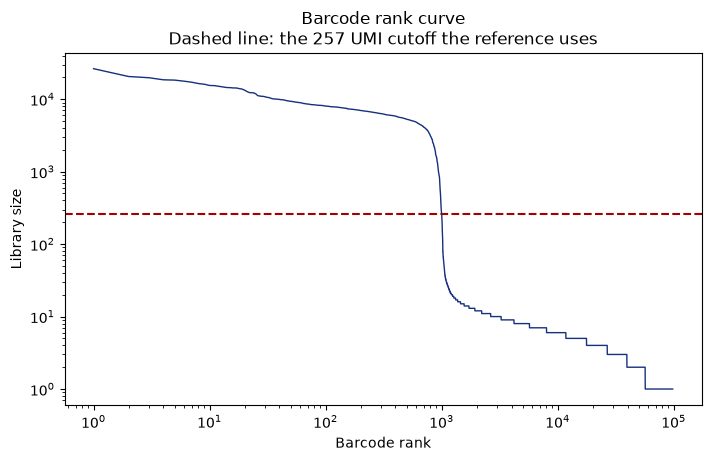

In [4]:
obs_raw = raw_object.obs(filtered=False)

lib_sorted = np.sort(obs_raw["lib_size"].to_numpy())[::-1]
rank = np.arange(1, lib_sorted.size + 1)

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
colours = bv.pl.bx_colors("main", n=3)

ax.plot(rank, lib_sorted, color=colours[1], linewidth=1)
ax.axhline(257, color=colours[0], linestyle="--")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Barcode rank")
ax.set_ylabel("Library size")
ax.set_title("Barcode rank curve\nDashed line: the 257 UMI cutoff the reference uses")
plt.show()

The cliff is obvious. Roughly a thousand barcodes sit well above it and
everything else falls off to single-digit libraries.

`bv.doublets.infer_empty_droplets()` is the Rust side of the three inference
methods, exposed so the calls can be compared before committing to one.

In [5]:
methods = {
    "umi_cutoff": EmptyDropletsParams(method="umi_cutoff", umi_cutoff=257),
    "expected_cells": EmptyDropletsParams(method="expected_cells", expected_cells=1000),
    "knee": EmptyDropletsParams(method="knee"),
}

lib_size = obs_raw["lib_size"].to_numpy()

rows = []
for name, params in methods.items():
    call = bv.doublets.infer_empty_droplets(lib_size, params)
    rows.append(
        {
            "method": name,
            "empty": int(call.sum()),
            "kept": int((~call).sum()),
            "min_kept_lib_size": int(lib_size[~call].min()),
        }
    )

comparison = pl.DataFrame(rows)

comparison

method,empty,kept,min_kept_lib_size
str,i64,i64,i64
"""umi_cutoff""",96998,1000,257
"""expected_cells""",96998,1000,257
"""knee""",96979,1019,120


`umi_cutoff` and `expected_cells` land on the same thousand barcodes, which they
should: the cutoff the notebook quotes is the one you get by asking for a
thousand cells. The knee detector stops at 120 UMIs instead of 257 and hands
back 19 extra barcodes. It is experimental in the reference too, so treat it as
a starting point rather than an answer.

We go with the cutoff.

In [6]:
empty_params = EmptyDropletsParams(method="umi_cutoff", umi_cutoff=257)

## Annotating the real cells

CellSweep needs cell type labels, so the real barcodes have to go through a
normal pipeline first. The raw object is not the place to do that, since 97k of
its barcodes are soup. Load the same file a second time with QC that means
something, and cluster there.

In [7]:
cell_object = bv.io.load_tenx_h5(
    dir_root / "cells",
    h5_path,
    qc=MinQualityParams(min_unique_genes=200, min_lib_size=257, min_cells=3),
    feature_type="Gene Expression",
    verbose=True,
)

cell_object

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading 10x matrix structure (shape: 737_280 cells x 36_620 features)...
  Features after type filtering: 36_601 / 36_620
First pass - gene expression statistics:
  Processed 10% of chunks (7/74)
  Processed 20% of chunks (14/74)
  Processed 30% of chunks (21/74)
  Processed 40% of chunks (28/74)
  Processed 50% of chunks (35/74)
  Processed 60% of chunks (42/74)
  Processed 70% of chunks (49/74)
  Processed 80% of chunks (56/74)
  Processed 90% of chunks (63/74)
  Processed 90% of chunks (70/74)
  Processed 100% of chunks (74/74)
First pass done: 11.09ms
  Genes passing filter: 15_015 / 36_601
Second pass - cell statistics:
  Processed 10% of chunks (7/74)
  Processed 20% of chunks (14/74)
  Processed 30% of chunks (21/74)
  Processed 40% of chunks (28/74)
  Processed 50% of chunks (35/74)
  Processed 60% of chunks (42/74)
  Processed 70% of chunks (49/74)
  Processed 80% of chunks (56/74)
  Processed 90% of chunks (63

  Counted 1_795_717 non-zeros over 15_015 genes in 1.11ms; converting in 1 phase(s).
  Phase 1/1: genes 0-15015, scatter 2.06ms, compress + write 45.11ms
  Conversion into gene-friendly format done: 49.56ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpzj7bwkq8/cells',
  cells=975 (kept 975), genes=15015,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

Standard QC on top: mitochondrial fraction, then MAD-based outlier detection
across the usual three metrics.

In [8]:
var_cells = cell_object.var()

bv.qc.gene_set_proportions(
    cell_object,
    {
        "MT": var_cells.filter(pl.col("gene_name").str.contains("^MT-"))[
            "gene_id"
        ].to_list()
    },
    streaming=False,
)

qc_df = cell_object.obs(cols=["cell_idx", "lib_size", "nnz", "MT"], filtered=True)

qc = bv.qc.run_cell_qc(
    {
        "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
        "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
        "MT": qc_df["MT"].to_numpy(),
    },
    cell_object.cells_to_keep,
    directions={
        "log10_lib_size": "twosided",
        "log10_nnz": "twosided",
        "MT": "above",
    },
    threshold=3.0,
)

cell_object.set_cells_to_keep(qc.cell_idx[~qc.combined])

int(qc.combined.sum())

Load in data: 1.64ms
Finished the gene set proportion calculations: 392.75µs


130

Then the pipeline, unchanged from any other single cell workflow.

In [9]:
bv.pp.find_hvg(cell_object, hvg_no=2000)

bv.pp.calculate_pca(cell_object, no_pcs=30, sparse_svd=True)

bv.graph.find_neighbours(
    cell_object, neighbours_params=NeighboursParams(knn_method="exhaustive")
)

bv.graph.find_clusters(cell_object, res=1.0, name="leiden_clusters")

obs_cells = cell_object.obs(filtered=True)

obs_cells["leiden_clusters"].value_counts().sort("leiden_clusters")

HVG (VST): 15_015 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 3.93ms
HVG (VST): Fitted Loess in 573.92µs
HVG (VST): Standardised variance in 442.46µs (424 gene(s) re-read for the clip)
HVG (VST): Total run time -> 4.99ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 757.04µs
Sparse PCA: finished the data preparations in 317.38µs
Sparse PCA: finished calculations in 67.21ms
Sparse PCA: total run time -> 68.31ms
Generating kNN data with exhaustive method.


Building Exhaustive index ...
... built Exhaustive index in 23.54µs
Generated Exhaustive index: 28.75µs
Querying Exhaustive index (self) ...
... queried Exhaustive index (self) in 1.00ms
Queried Exhaustive index: 1.02ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 1.99ms


leiden_clusters,count
i32,u32
0,243
1,233
2,89
3,82
4,81
5,36
6,36
7,32
8,13


In [10]:
n_cells = obs_cells.height
n_clusters = obs_cells["leiden_clusters"].n_unique()
print(f"{n_cells} cells over {n_clusters} clusters")

845 cells over 9 clusters


Good enough to subtract against; you would name them with
`bv.annotate.calc_sc_type_scores()` or a reference in a real analysis, but the
model only cares that barcodes with the same label share a profile.

## Putting the labels back

The labels live on the cell object and CellSweep reads them off the raw one, so
they have to be joined across by barcode. Every barcode that is not a clustered
cell keeps a null, which is exactly how `cellsweep()` finds the barcodes it
should ignore.

In [11]:
labels = obs_raw.select("cell_idx", "cell_id").join(
    obs_cells.select(
        "cell_id",
        pl.format("cluster_{}", pl.col("leiden_clusters")).alias("cell_type"),
    ),
    on="cell_id",
    how="left",
)

raw_object.add_obs(
    labels.select("cell_idx", "cell_type").with_columns(sample_id=pl.lit("pbmc_1k"))
)

labels["cell_type"].value_counts().sort("cell_type")

cell_type,count
str,u32
null,97153
"""cluster_0""",243
"""cluster_1""",233
"""cluster_2""",89
"""cluster_3""",82
"""cluster_4""",81
"""cluster_5""",36
"""cluster_6""",36
"""cluster_7""",32


Watch the null handling there. Formatting the label before the join keeps the
unmatched barcodes null. Paste a prefix onto the joined column the wrong way
and you get the string `"cluster_null"`, and CellSweep will happily treat those
barcodes as one more cell type and fit a profile to them. Keep the null a null.

`sample_id` is a constant here because this is one emulsion. It is still
required: the ambient profile is a property of a single run, and pooling samples
into one profile is wrong even when it runs.

## Running CellSweep

In [12]:
clean_object = bv.doublets.cellsweep(
    dir_root / "clean",
    raw_object,
    celltype_column="cell_type",
    sample_column="sample_id",
    empty_params=empty_params,
    verbose=True,
)

clean_object

Empty droplets (method 'umi_cutoff'): 96998 of 97998 barcodes called empty.


155 barcodes are neither empty nor annotated-and-passing-QC. They are excluded from the fit and from the output.


Running CellSweep over 1 samples, 845 barcodes, 96998 empty droplets.


CellSweep: 1 samples, 845 barcodes to denoise, 36601 genes
  Sample 1/1 ('pbmc_1k'): 845 barcodes, 96_998 empty droplets


   332 EM iterations, converged = true, ll = -378.745659, beta = 0.000013
Generating gene-based binary.
CellSweep finished in 1.97s


  Counted 1_633_280 non-zeros over 36_601 genes in 3.06ms; converting in 1 phase(s), carrying the norm.


  Phase 1/1: genes 0-36601, scatter 6.02ms, compress + write 178.37ms
  Conversion into gene-friendly format done: 189.10ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpzj7bwkq8/clean',
  cells=845 (kept 845), genes=36601,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

Three numbers in that output are worth reading. 96,998 barcodes went into the
ambient profile. 845 got denoised. And 155 barcodes were neither: they cleared
the UMI cutoff but failed QC or the outlier check, so they have no label to
subtract against. Those are dropped from the fit and from the output, which is
why the clean object is 845 cells and not 1000.

The denoised counts land in a new directory. The raw layer takes stochastically
rounded values so the negative binomial methods downstream still see integers,
and the normalised layer keeps the float magnitudes.

## What came out

The ambient profile is the first thing to look at, because it is the one part of
the fit you can sanity check against what you know about the tissue.

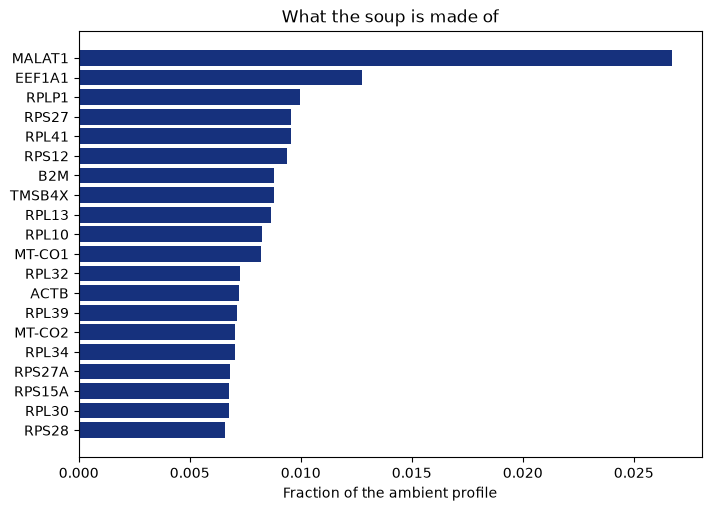

In [13]:
var_clean = clean_object.var()

top_ambient = var_clean.sort("cellsweep_ambient", descending=True).head(20)

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.barh(
    top_ambient["gene_name"].to_list()[::-1],
    top_ambient["cellsweep_ambient"].to_numpy()[::-1],
    color=colours[1],
)
ax.set_xlabel("Fraction of the ambient profile")
ax.set_title("What the soup is made of")
plt.show()

MALAT1, elongation factors, ribosomal proteins, B2M, mitochondrial genes. That
is the soup of a lysing PBMC and nothing else, which is a good sign.

Next, the per-barcode contamination.

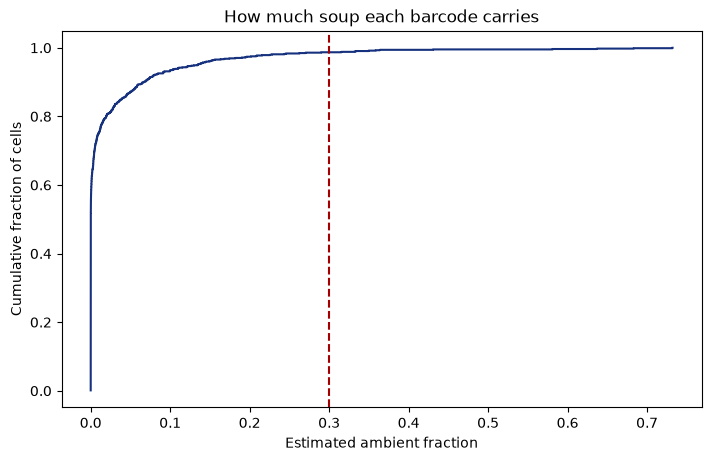

In [14]:
obs_clean = clean_object.obs(filtered=False)

alpha = np.sort(obs_clean["cellsweep_alpha"].to_numpy())
ecdf = np.arange(1, alpha.size + 1) / alpha.size

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.step(alpha, ecdf, where="post", color=colours[1])
ax.axvline(0.3, color=colours[0], linestyle="--")
ax.set_xlabel("Estimated ambient fraction")
ax.set_ylabel("Cumulative fraction of cells")
ax.set_title("How much soup each barcode carries")
plt.show()

In [15]:
obs_clean["cellsweep_alpha"].describe()

statistic,value
str,f64
"""count""",845.0
"""null_count""",0.0
"""mean""",0.022825
"""std""",0.067606
"""min""",7.9420e-20
"""25%""",8.7661e-7
"""50%""",0.000107
"""75%""",0.009736
"""max""",0.732062


In [16]:
obs_clean.group_by("cell_type").agg(
    n=pl.len(), median_alpha=pl.col("cellsweep_alpha").median()
).sort("median_alpha", descending=True)

cell_type,n,median_alpha
str,u32,f64
"""cluster_1""",233,0.01148
"""cluster_3""",82,0.000116
"""cluster_0""",243,0.000103
"""cluster_2""",89,0.000016
"""cluster_8""",13,0.000014
"""cluster_6""",36,0.000006
"""cluster_7""",32,0.000002
"""cluster_5""",36,4.1795e-7
"""cluster_4""",81,2.4807e-7


This run is clean. The median barcode is essentially uncontaminated and only a
handful sit above the 0.3 the reference notebook filters at. That is not always
what you get, and it is worth knowing before you assume your lineage markers are
real.

### Does the subtraction do anything?

The honest test is not whether alpha looks plausible but whether the counts
change in the direction they should. Monocyte genes appearing in T cells are
soup by construction, so track a couple of them across clusters, before and
after.

In [17]:
markers = {"LYZ": "monocyte", "S100A8": "monocyte", "PPBP": "platelet"}
marker_ids = dict(
    var_clean.filter(pl.col("gene_name").is_in(list(markers)))
    .select("gene_id", "gene_name")
    .iter_rows()
)


def detection_rate(object, layer_name):
    expr = bv.pl.extract_gene_expression(
        object, list(marker_ids), obs_cols=["cell_type"]
    ).filter(pl.col("cell_type").is_not_null())
    return (
        expr.unpivot(
            index=["cell_id", "cell_type"], variable_name="gene_id", value_name="expr"
        )
        .with_columns(gene=pl.col("gene_id").replace_strict(marker_ids))
        .group_by("gene", "cell_type")
        .agg(detected=(pl.col("expr") > 0).mean())
        .with_columns(layer=pl.lit(layer_name))
    )


rates = pl.concat(
    [detection_rate(raw_object, "raw"), detection_rate(clean_object, "denoised")]
)

with pl.Config(tbl_rows=-1):
    print(
        rates.pivot("layer", index=["gene", "cell_type"], values="detected").sort(
            "gene", "cell_type"
        )
    )

shape: (27, 4)
┌────────┬───────────┬──────────┬──────────┐
│ gene   ┆ cell_type ┆ raw      ┆ denoised │
│ ---    ┆ ---       ┆ ---      ┆ ---      │
│ str    ┆ str       ┆ f64      ┆ f64      │
╞════════╪═══════════╪══════════╪══════════╡
│ LYZ    ┆ cluster_0 ┆ 0.012346 ┆ 0.0      │
│ LYZ    ┆ cluster_1 ┆ 0.987124 ┆ 0.982833 │
│ LYZ    ┆ cluster_2 ┆ 0.011236 ┆ 0.0      │
│ LYZ    ┆ cluster_3 ┆ 0.0      ┆ 0.0      │
│ LYZ    ┆ cluster_4 ┆ 0.012346 ┆ 0.0      │
│ LYZ    ┆ cluster_5 ┆ 0.0      ┆ 0.0      │
│ LYZ    ┆ cluster_6 ┆ 0.027778 ┆ 0.0      │
│ LYZ    ┆ cluster_7 ┆ 0.0      ┆ 0.0      │
│ LYZ    ┆ cluster_8 ┆ 0.923077 ┆ 0.923077 │
│ PPBP   ┆ cluster_0 ┆ 0.0      ┆ 0.0      │
│ PPBP   ┆ cluster_1 ┆ 0.038627 ┆ 0.021459 │
│ PPBP   ┆ cluster_2 ┆ 0.0      ┆ 0.0      │
│ PPBP   ┆ cluster_3 ┆ 0.0      ┆ 0.0      │
│ PPBP   ┆ cluster_4 ┆ 0.0      ┆ 0.0      │
│ PPBP   ┆ cluster_5 ┆ 0.0      ┆ 0.0      │
│ PPBP   ┆ cluster_6 ┆ 0.0      ┆ 0.0      │
│ PPBP   ┆ cluster_7 ┆ 0.0      ┆ 0.0   

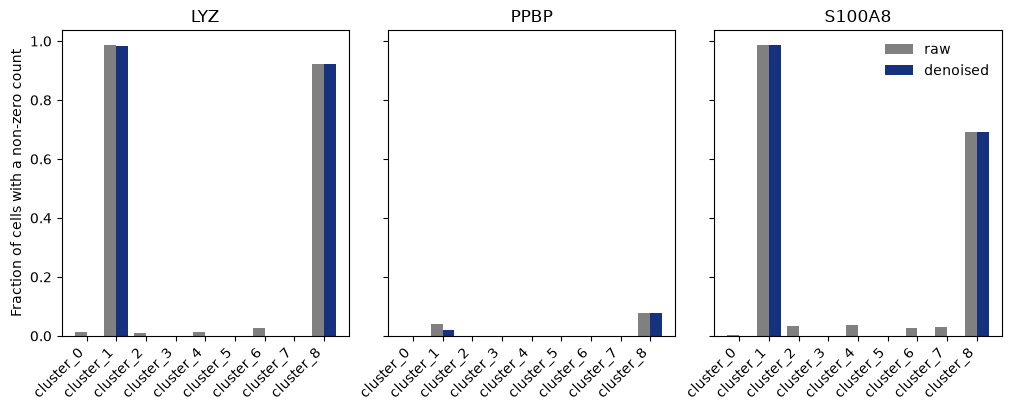

In [18]:
cell_types = sorted(rates["cell_type"].unique().to_list())
x = np.arange(len(cell_types))
width = 0.4
layer_colours = {"raw": "grey", "denoised": colours[1]}

fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharey=True, layout="constrained")
for ax, gene in zip(axes, sorted(markers), strict=True):
    for offset, layer in ((-width / 2, "raw"), (width / 2, "denoised")):
        sub = rates.filter((pl.col("gene") == gene) & (pl.col("layer") == layer))
        lookup = dict(sub.select("cell_type", "detected").iter_rows())
        ax.bar(
            x + offset,
            [lookup.get(ct, 0.0) for ct in cell_types],
            width,
            color=layer_colours[layer],
            label=layer,
        )
    ax.set_title(gene)
    ax.set_xticks(x, cell_types, rotation=45, ha="right")
axes[0].set_ylabel("Fraction of cells with a non-zero count")
axes[-1].legend(frameon=False)
plt.show()

Cluster 1 is the monocytes and it keeps LYZ and S100A8 in essentially every
cell. The small myeloid cluster 8 keeps exactly the rates it came in with, 92%
for LYZ and 69% for S100A8. Everywhere else those genes were
showing up in a few percent of barcodes before the sweep and are gone
afterwards. PPBP does the same thing in reverse: platelet transcripts leaking
into the monocytes roughly halve. The subtraction went after the right counts.

## Reprocessing the clean counts

Feature selection and reduction were computed on contaminated counts, so they
have to be redone. Drop the barcodes CellSweep says are mostly soup while you
are at it.

In [19]:
clean_object.set_cells_to_keep(
    obs_clean.filter(pl.col("cellsweep_alpha") <= 0.3)["cell_idx"].to_numpy()
)

bv.pp.find_hvg(clean_object, hvg_no=2000)

bv.pp.calculate_pca(clean_object, no_pcs=30, sparse_svd=True)

bv.graph.find_neighbours(
    clean_object, neighbours_params=NeighboursParams(knn_method="exhaustive")
)

bv.embed.umap(clean_object)

clean_object

HVG (VST): 36_601 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 4.43ms
HVG (VST): Fitted Loess in 1.93ms
HVG (VST): Standardised variance in 343.04µs (318 gene(s) re-read for the clip)
HVG (VST): Total run time -> 6.77ms


Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 708.46µs
Sparse PCA: finished the data preparations in 247.88µs
Sparse PCA: finished calculations in 77.34ms
Sparse PCA: total run time -> 78.33ms
Generating kNN data with exhaustive method.


Building Exhaustive index ...
... built Exhaustive index in 20.29µs
Generated Exhaustive index: 27.04µs
Querying Exhaustive index (self) ...
... queried Exhaustive index (self) in 1.02ms
Queried Exhaustive index: 1.04ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 2.39ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpzj7bwkq8/clean',
  cells=845 (kept 834), genes=36601,
  hvg=True, pca=True, embeddings=['umap'],
  knn=True, graph=True, magic=False, residuals=False,
  stale=none
)

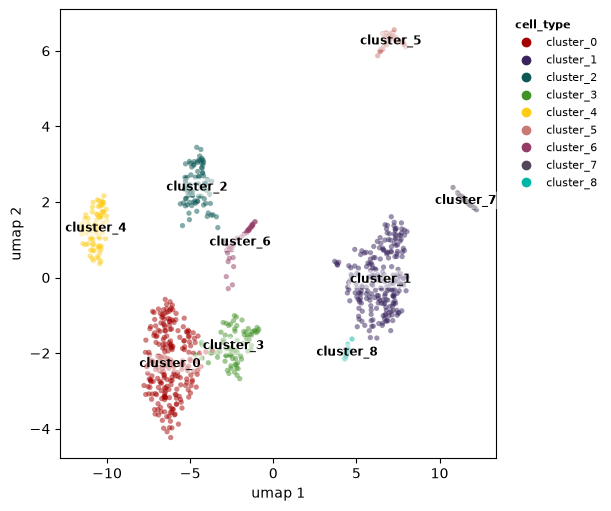

In [20]:
bv.pl.embedding_plot(
    clean_object,
    "umap",
    "cell_type",
    label_by="cell_type",
    discrete=True,
)
plt.show()

The clusters survive the sweep, which is what you want. CellSweep is not
supposed to rearrange your populations, it is supposed to stop the space between
them being filled with borrowed transcripts. If your structure falls apart after
denoising, the labels you handed it were wrong.

## Where this goes next

The obvious extension is multi-sample data, where the ambient profile is fitted
per emulsion and `sample_column` starts earning its keep. A soup that differs
between runs is a batch effect that no correction method will name for you, and
having `cellsweep_alpha` and the per-sample profiles in hand is a much better
starting point than pretending the contamination is uniform.

`cellsweep_alpha` is also worth keeping in the obs table after the fact. It is a
QC metric in its own right, and a cluster with a suspiciously high median is
usually debris rather than biology.

## Clean up

In [21]:
tempdir_cellsweep.cleanup()